<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/machine-learning/ch05_decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Trees

pg - 199

* Decision trees is an versatile machine learning algorithm that can perform both classification and regression tasks , and even multioutput tasks .




`Discussions`

1. In this chapter we will start by discussing how to train, visualize, and make predictions with decision tree,

2. go through the CART training algorithm used by Scikit-Learn

3. we will explore how to regularize trees and use them
for regression tasks

4. discuss some of the limitations of decision trees.

Multilabel classification means each sample can belong to several classes at once, and the labels are independent of each other. Think of tagging a photo with “beach,” “sunset,” and “people.” Each tag is a yes/no decision, and the output for one sample is a set of tags. The target is a binary matrix with one column per label.

Multioutput classification is a broader setting where each output can take more than two values. The outputs are separate targets, and each one is a multiclass decision. For example, predicting both the color (red, green, blue) and the size (S, M, L, XL) of a shirt from one set of features. The target is a matrix where each column has its own set of class valu

## 0.Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from packaging import version
from pathlib import Path


## 1.Training and Visualizing a Decision Tree



In [ ]:
# DecisionTreeClassifier on the iris dataset

# Let's code it out
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris = load_iris(as_frame = True)
X_iris = iris.data[["petal length (cm)" , "petal width (cm)"]]
y_iris = iris.target

In [ ]:
X_iris[:3]

,petal length (cm),petal width (cm)
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2


In [ ]:
y_iris[:3]

,target
0,0
1,0
2,0


In [ ]:
tree_clf = DecisionTreeClassifier(max_depth = 2, random_state = 42)
tree_clf.fit(X_iris , y_iris)


DecisionTreeClassifier(max_depth=2, random_state=42)

let's visualize the trained decision tree by first using the export_graphviz() function to output a graph definition file calles iris_tree.dot

`export_graphviz`

* It's a scikit-learn function that converts a trained decision tree into a text file in DOT format. DOT is the language used by Graphviz, an open-source tool for drawing graphs.

* Graphviz is an open source graph visualization software package. It also includes a dot command-line tool to convert
.dot files to a variety of formats, such as PDF or PNG.

In [ ]:
# Let's code it out
from sklearn.tree import export_graphviz

export_graphviz(
    tree_clf ,
    out_file = "iris_tree.dot",
    feature_names = ["petal length (cm)", "petal width (cm)"],
    class_names = iris.target_names,
    rounded = True,
    filled = True
)


Now  we can use graphviz.Source.from_file() to load and display the file

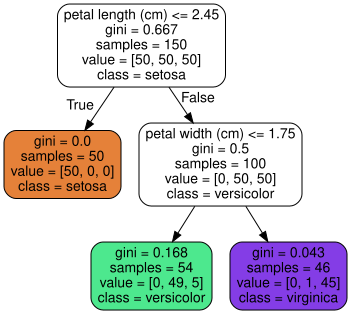

In [ ]:
from graphviz import Source
Source.from_file("iris_tree.dot")

### 1.1 Making predicitions



`NOTE`


One of the many qualities of decision trees is that they require very little data preparation. In fact, they don’t require
feature scaling or centering at all.

* A node’s samples attribute counts how many training instances it applies to.

* A node’s value attribute tells you how many training instances of each class this node applies to.

* a node’s gini attribute
measures its Gini impurity: a node is “pure” (gini=0) if all training instances it applies to belong to the same class.

### 1.2 `Gini Impurity`

$$G_i = 1 - \sum_{k=1}^{n} p_{i,k}^2$$

For example, the depth-2 left node has a Gini impurity equal to 1 – (0/54)2 – (49/54)2 – (5/54)2 ≈ 0.168.

`The equation :`

* $G_i$ is the Gini impurity of the i^th node.

* p_i,k is the ratio of class k instances among the training instances in the i^th node.

`NOTE`

Scikit-Learn uses the `CART algorithm` (discussed shortly), which produces only binary trees, meaning trees where
split nodes always have exactly two children `(i.e., questions only have yes/no answers).` However, other algorithms,
such as ID3, can produce decision trees with nodes that have more than two children.

### 1.3 Extra info

shows this decision tree’s decision boundaries. The thick vertical line represents the decision boundary of the
root node (depth 0): petal length = 2.45 cm. Since the lefthand area is pure (only Iris setosa), it cannot be split any
further. However, the righthand area is impure, so the depth-1 right node splits it at petal width = 1.75 cm (represented by
the dashed line). Since max
_
depth was set to 2, the decision tree stops right there. If you set max
_
depth to 3, then the
two depth-2 nodes would each add another decision boundary (represented by the two vertical dotted lines).

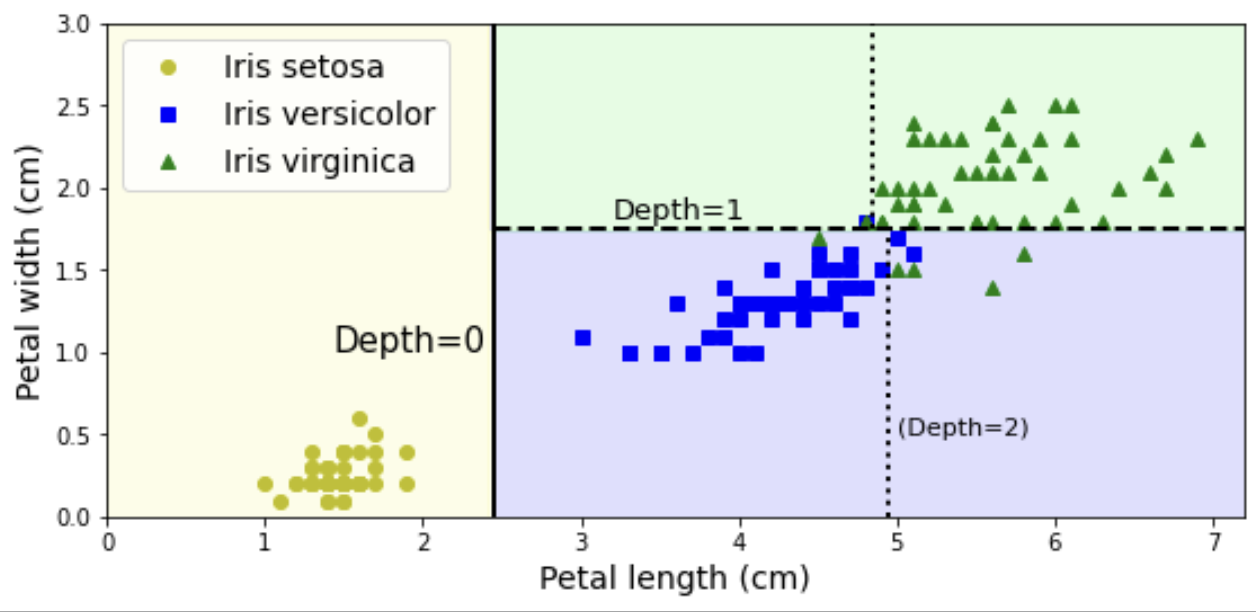

In [ ]:
help(tree_clf.tree_)

Help on Tree object:

class Tree(builtins.object)
 |  Array-based representation of a binary decision tree.
 |
 |  The binary tree is represented as a number of parallel arrays. The i-th
 |  element of each array holds information about the node `i`. Node 0 is the
 |  tree's root. You can find a detailed description of all arrays in
 |  `_tree.pxd`. NOTE: Some of the arrays only apply to either leaves or split
 |  nodes, resp. In this case the values of nodes of the other type are
 |  arbitrary!
 |
 |  Attributes
 |  ----------
 |  node_count : intp_t
 |      The number of nodes (internal nodes + leaves) in the tree.
 |
 |  capacity : intp_t
 |      The current capacity (i.e., size) of the arrays, which is at least as
 |      great as `node_count`.
 |
 |  max_depth : intp_t
 |      The depth of the tree, i.e. the maximum depth of its leaves.
 |
 |  children_left : array of intp_t, shape [node_count]
 |      children_left[i] holds the node id of the left child of node i.
 |      For lea

`NOTE`

1. Decision trees - white box models
2. Random forests and neural networks - black box models

### 1.4 Estimating Class Probabilities

* A decision tree can also estimate the probability that an instance belongs to a particular class k.

HOW ?   
1. First it traverses the tree
to find the leaf node for this instance,
2. then it returns the proportion of instances of class k among the training instances that would also reach this leaf node.


In [ ]:
# Let's test it out
import pandas as pd
tree_clf.predict_proba(pd.DataFrame([[5, 1.5]] ,
                                    columns = ["petal length (cm)",
                                               "petal width (cm)"])).round(3)

# the probabilites should be :-
# 0 %    - iris setosa
# 90.7 % - iris versicolor
# 9.3 %  - iris virginica

array([[0.   , 0.907, 0.093]])

In [ ]:
tree_clf.predict(pd.DataFrame([[5, 1.5]],
                              columns = ["petal length (cm)",
                                         "petal width (cm)"])).round(2)


array([1])

### 1.5 The CART Training algorithm

Scikit-Learn uses the Classification and Regression Tree (CART) algorithm to train decision trees (also called “growing”
trees)

Working -

* The algorithm works by first splitting the training set into two subsets using a single feature k and a threshold $t_k$

* Once the CART algorithm has successfully split the training set in two, it splits the subsets using the same logic, then the
sub-subsets, and so on, recursively

* It `stops recursing` once it reaches the `maximum depth` (defined by the max_depth hyperparameter), or if it cannot find a split that will reduce `impurity.`

EXTRA

A few other hyperparameters controls additional stopping conditions:
* min_samples_split
*  min_samples_leaf
* max_leaf_nodes,
and many more.

How to choose k And $t_k$

*  It searches for the pair (k, $t_k$) that produces the purest
subsets, weighted by their size.

#### 1.5.1 CART cost function for classification

`Below`


equation gives the cost function that the algorithm tries to minimize.

$$J(k, t_k) = \frac{m_{\text{left}}}{m} G_{\text{left}} + \frac{m_{\text{right}}}{m} G_{\text{right}}$$


where

$G_{\text{left/right}}$ measures the impurity of the left/right subset

$m_{\text{left/right}}$ is the number of instances in the left/right subset

$m = m_{\text{left}} + m_{\text{right}}$

CART chooses the feature $k$ and threshold $t_k$ that make this weighted impurity as small as possible.

`NOTE`

* CART Algorithm is  greedy algorithm , as it greedily searches for an optimum split at the top level,
then repeats the process at each subsequent level ,

  Also ,
*  It does not check whether the split will lead to the lowest possible
impurity several levels down.



`TBR` A greedy algorithm often produces a solution that’s reasonably good but not
guaranteed to be optimal.



---



`Computational Complexity `

* Making predictions requires traversing the decision tree from the root to a leaf.

* Decision trees are generally
approximately balanced,so

  Traversing the decision tree requires going through roughly O
  $(log_2(m))$ nodes,
  
  where m is the number of training instances, and $log_2(m)$ is the binary logarithm of m, equal to log(m) / log(2).

REMEMBER - each node only
requires checking the value of one feature, so overall prediction complexity is O($log_2(m)$)

`Complexity being indepented on no. of features `

0 ---

`THIS IS THE REAL DEAL `

By default, the training algorithm compares all features on all samples at each node, which results in a training
complexity of O(n × m $log_2(m)$).

0---

---

## 2.Gini Impurity or Entropy

The DecisionTreeClassifier Class uses the Gini Impurity by default ,

We can also select the entropy impurity measure instead of setting the criterion hyperparamter to "entropy".



In thermodynamics as a measure of molecular disorder: entropy approaches zero when molecules are still and well
ordered

In ML , a set’s entropy is zero when it contains instances of
only one class

Equation that shows the definition of the entropy of the i^th node.

`Entropy`


$$H_i = -\sum_{\substack{k=1 \\ p_{i,k} \neq 0}}^{n} p_{i,k} \log_2(p_{i,k})$$

For example, the depth-2 left node in
Cell 7 has an entropy equal to –(49/54) log2 (49/54) – (5/54) log2 (5/54) ≈ 0.445.

Between the Gini impurity and entropy

* the Gini impurtiy is slightly faster to compute, a good default

* Gini impurity
tends to isolate the most frequent class in its own branch of the tree, while entropy tends to produce slightly more
balanced trees.⁠



---



## 3.Regularization Hyperparameters

To avoid overfitting the training data, you need to restrict the decision tree’s freedom during training and that's what called regularization

The regularization hyperparameters depend on the algorithm used, but generally you
can at least restrict the maximum depth of the decision tree
by using the max_depth hyperparameter
and the default value is None( which means unlimited ).



Some Parameters that similarly restrict the shape of the decision tree :

1. `max_features` - Maximum number of features that are evaluated for splitting at each node.

2. `max_leaf_nodes` - Maximum number of leaf nodes

3. `min_samples_split` - Minimum no. of samples a node must have before it can be split

4. `min_samples_leaf` - Minimum no. of samples a leaf node must have to be created

5. `min_weight_fraction_leaf` - same as min_samples_leaf but expressed as a fraction of the total number if weighted instances

6. `ccp_alpha` - Controls minimal cost-complexity pruning (MCCP), i.e., pruning subtrees that don’t reduce impurity
enough compared to their number of leaves; a larger ccp_
alpha value leads to more pruning,
resulting in a smaller tree (the default is 0—no pruning)

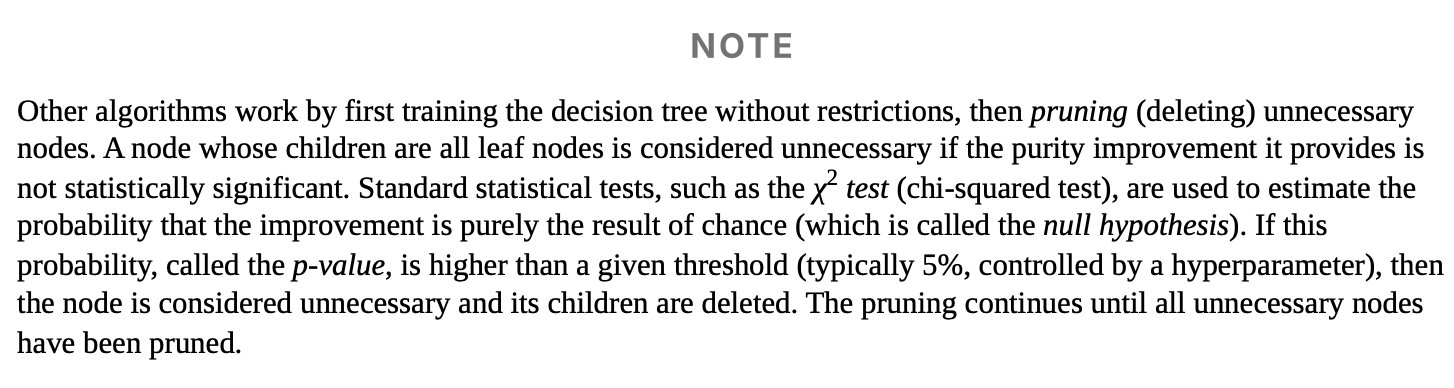

Let’s test regularization on the moons dataset: this is a toy dataset for binary classification in which the data points are
shaped as two interleaving crescent moons

We’ll train one decision tree without regularization, and another with min
_
samples
leaf=5.

In [ ]:
# Without regularization and with min_samples_leaf
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
X_moons , y_moons = make_moons(n_samples = 150 , noise = 0.2 ,random_state = 42)

tree_clf1 = DecisionTreeClassifier(random_state = 42)
tree_clf2 = DecisionTreeClassifier(min_samples_leaf = 5 , random_state = 42)


In [ ]:
tree_clf1.fit(X_moons , y_moons)

DecisionTreeClassifier(random_state=42)

In [ ]:
tree_clf2.fit(X_moons , y_moons)

DecisionTreeClassifier(min_samples_leaf=5, random_state=42)

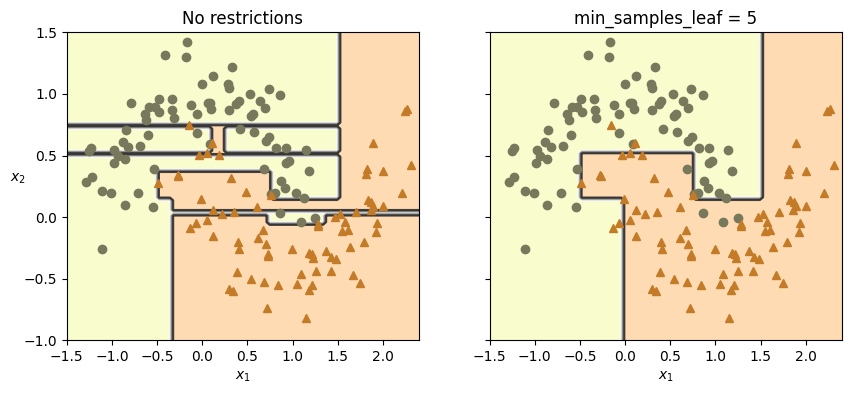

In [ ]:
# extra code – this cell generates and saves Figure 6–3

def plot_decision_boundary(clf, X, y, axes, cmap):
    x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 100),
                         np.linspace(axes[2], axes[3], 100))
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)

    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=cmap)
    plt.contour(x1, x2, y_pred, cmap="Greys", alpha=0.8)
    colors = {"Wistia": ["#78785c", "#c47b27"], "Pastel1": ["red", "blue"]}
    markers = ("o", "^")
    for idx in (0, 1):
        plt.plot(X[:, 0][y == idx], X[:, 1][y == idx],
                 color=colors[cmap][idx], marker=markers[idx], linestyle="none")
    plt.axis(axes)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$", rotation=0)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf1, X_moons, y_moons,
                       axes=[-1.5, 2.4, -1, 1.5], cmap="Wistia")
plt.title("No restrictions")
plt.sca(axes[1])
plot_decision_boundary(tree_clf2, X_moons, y_moons,
                       axes=[-1.5, 2.4, -1, 1.5], cmap="Wistia")
plt.title(f"min_samples_leaf = {tree_clf2.min_samples_leaf}")
plt.ylabel("")

plt.show()

The unregularized model on the left is clearly overfitting, and the regularized model on the right will probably generalize
better.

In [ ]:
# Let's verify this by evaluating both trees on a test set generated using random seed

X_moons_test , y_moons_test = make_moons(n_samples = 1000 , noise = 0.2 ,random_state = 42)
len(X_moons_test) , len(y_moons_test) , X_moons_test.shape , y_moons_test.shape


(1000, 1000, (1000, 2), (1000,))

`.score()` - This returns a value between 0 and 1.

example, 0.98 means 98% of the samples were classified correctly.

In [ ]:
tree_clf1.score(X_moons_test, y_moons_test)

0.901

HERE , clearly the second tree (min_samples_leaf) have a better accuracy on the test set.

In [ ]:
tree_clf2.score(X_moons_test, y_moons_test)

0.918

## 4.Regression

Decision trees are also capable of performing regression tasks.

While linear regression only works well with linear data,
`decision trees` can fit all sorts of `complex datasets.`

Buidling an regression tree , by using Scikit-Learn’s
DecisionTreeRegressor class, and training it on a noisy quadratic dataset with max_depth=2

In [ ]:
# Building an regression tree
import numpy as np
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(seed = 42)
X_quad = rng.random((200,1)) - 0.5 # a single random input feature
# X_quad here -0.5 means range will be (-0.5 to 0.5)

y_quad = X_quad ** 2 + 0.025 * rng.standard_normal((200,1)) # random quadratic equation

# creating an instance
tree_reg = DecisionTreeRegressor(max_depth = 2 , random_state = 42)
tree_reg.fit(X_quad , y_quad)


DecisionTreeRegressor(max_depth=2, random_state=42)

In [ ]:
print(X_quad.max().round(2))
print(X_quad.min().round(2))

0.49
-0.49


In [ ]:
# let's code the epxport_graphviz
from sklearn.tree import export_graphviz

export_graphviz(
    tree_reg,
    out_file = "regression_tree.dot",
    feature_names = ["x1"],
    rounded = False , # just for the rounded edges to the boxes/nodes
    filled = True # jsut adding color to the boxes
)


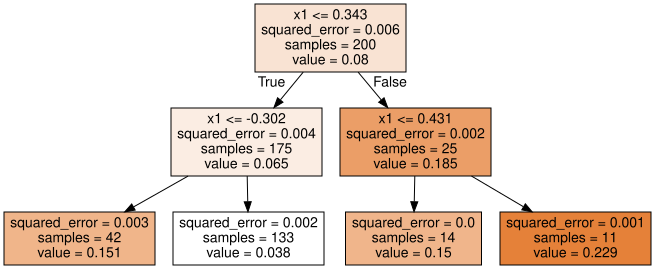

In [ ]:
from graphviz import Source
Source.from_file("regression_tree.dot")

The difference from the other decision tree we created is that here instead of predicting a class in each node , it predicts a value .



1. Sample (instance): one row of data, a single pair (x₁, y). X_quad has 200 samples, so the root node says samples = 200. A node’s samples is how many training rows fall into that node.

2. Target: the y value you’re trying to predict, from y_quad. Each sample has one target.

3. value: the average of the targets in that node. This is the tree’s prediction for any input that lands there. For the leaf with 133 samples, value = 0.038.

4. squared_error: how spread out the targets are around that average. It’s the mean of (y − value)² over the node’s samples. Small means the targets are close to the prediction. The root has squared_error = 0.006, and the leaf has 0.002, so the leaf’s targets are tightly clustered.



---



`NOTE`

* the predicted value for each region is always the average target value of the
instances in that region. The algorithm splits each region in a way that makes most training instances as close as possible
to that predicted value.

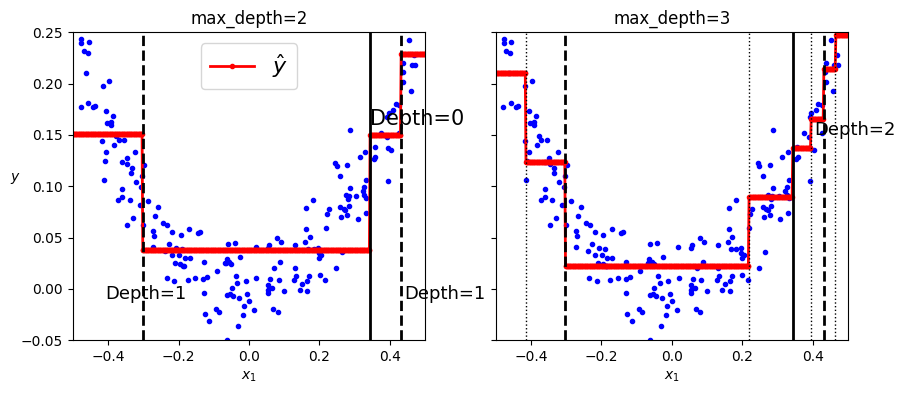

In [ ]:
# extra code – this cell generates and saves Figure 6–5
tree_reg2 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_reg2.fit(X_quad, y_quad)

def plot_regression_predictions(tree_reg, X, y, axes=[-0.5, 0.5, -0.05, 0.25]):
    x1 = np.linspace(axes[0], axes[1], 500).reshape(-1, 1)
    y_pred = tree_reg.predict(x1)
    plt.axis(axes)
    plt.xlabel("$x_1$")
    plt.plot(X, y, "b.")
    plt.plot(x1, y_pred, "r.-", linewidth=2, label=r"$\hat{y}$")

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_regression_predictions(tree_reg, X_quad, y_quad)

th0, th1a, th1b = tree_reg.tree_.threshold[[0, 1, 4]]
for split, style in ((th0, "k-"), (th1a, "k--"), (th1b, "k--")):
    plt.plot([split, split], [-0.05, 0.25], style, linewidth=2)
plt.text(th0, 0.16, "Depth=0", fontsize=15)
plt.text(th1a + 0.01, -0.01, "Depth=1", horizontalalignment="center", fontsize=13)
plt.text(th1b + 0.01, -0.01, "Depth=1", fontsize=13)
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper center", fontsize=16)
plt.title("max_depth=2")

plt.sca(axes[1])
th2s = tree_reg2.tree_.threshold[[2, 5, 9, 12]]
plot_regression_predictions(tree_reg2, X_quad, y_quad)
for split, style in ((th0, "k-"), (th1a, "k--"), (th1b, "k--")):
    plt.plot([split, split], [-0.05, 0.25], style, linewidth=2)
for split in th2s:
    plt.plot([split, split], [-0.05, 0.25], "k:", linewidth=1)
plt.text(th2s[2] + 0.01, 0.15, "Depth=2", fontsize=13)
plt.title("max_depth=3")

plt.show()



---



###4.1 CART Cost function for reegression

The CART algorithm works as described earlier, except that instead of trying to split the training set in a way that
minimizes impurity, it now tries to split the training set in a way that minimizes the MSE

 CART cost function for regression

$$J(k, t_k) = \frac{m_{\text{left}}}{m} \text{MSE}_{\text{left}} + \frac{m_{\text{right}}}{m} \text{MSE}_{\text{right}}$$

where ,

$$\text{MSE}_{\text{node}} = \frac{\sum_{i \in \text{node}} (\hat{y}_{\text{node}} - y^{(i)})^2}{m_{\text{node}}}$$

$$\hat{y}_{\text{node}} = \frac{\sum_{i \in \text{node}} y^{(i)}}{m_{\text{node}}}$$

This is the cost function that algorithm tries to minimize

A cost function is a formula that measures how bad a model’s choice is. The training algorithm tries to make this number as small as possible.

For a decision tree, the choice is where to split. Each candidate split gets a cost, and CART picks the split with the lowest cost.

---

Overfitting in Regression Trees

- **Default tree (no restrictions):** grows until every leaf is tiny, so it fits the noise and zigzags through every point. Training error is near zero, but it generalizes poorly.
- **`min_samples_leaf=10`:** each leaf must contain at least 10 training instances, so the tree stops splitting early. The predictions become smooth steps that follow the overall trend.
- **Takeaway:** regularize the tree by limiting how small or deep it can grow. More restrictions reduce overfitting but can cause underfitting if pushed too far.

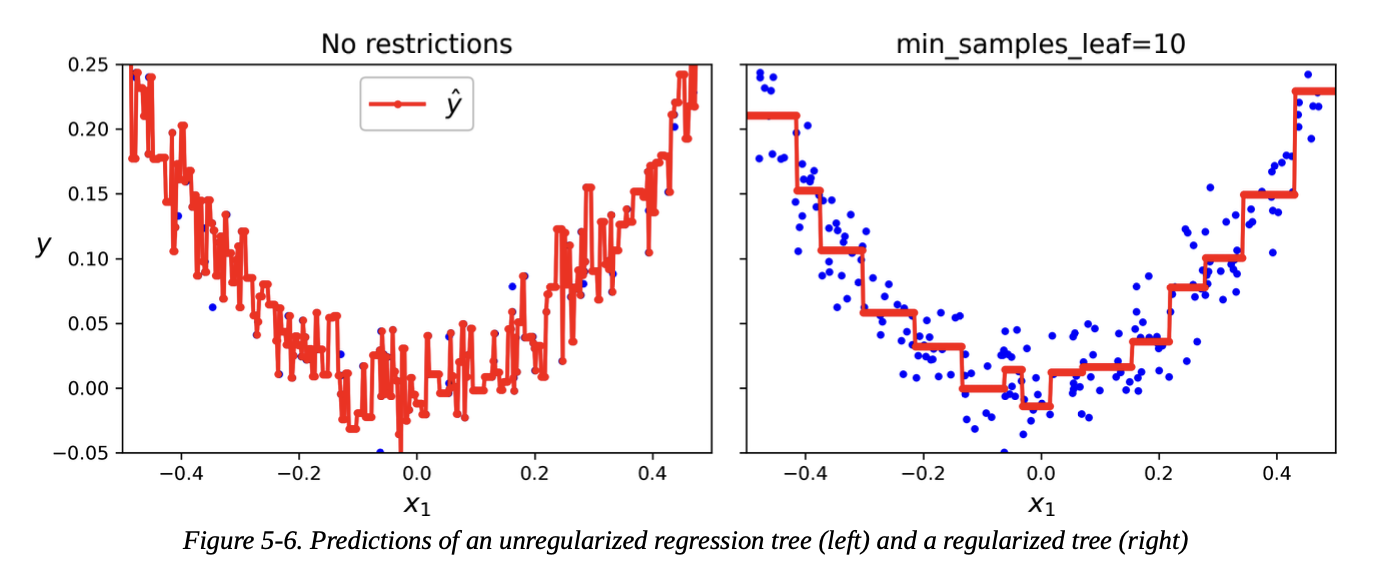



---



## 5.Sensitivity to Axis Orientation


decision trees have a lot going for them: they are relatively easy to understand
and interpret, simple to use, versatile, and powerful. However, they do have a few limitations. First, as you may have
noticed, decision trees love orthogonal decision boundaries (all splits are perpendicular to an axis), which makes them
sensitive to the data’s orientation.

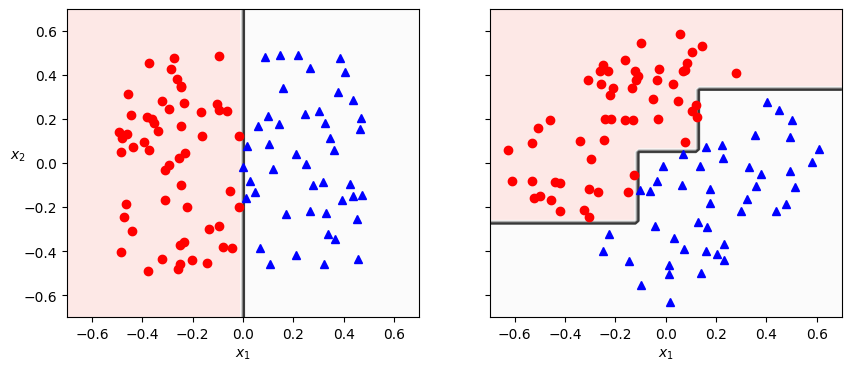

In [ ]:
# extra code – this cell generates and saves Figure 6–7

np.random.seed(6)
X_square = np.random.rand(100, 2) - 0.5
y_square = (X_square[:, 0] > 0).astype(np.int64)

angle = np.pi / 4  # 45 degrees
rotation_matrix = np.array([[np.cos(angle), -np.sin(angle)],
                            [np.sin(angle), np.cos(angle)]])
X_rotated_square = X_square.dot(rotation_matrix)

tree_clf_square = DecisionTreeClassifier(random_state=42)
tree_clf_square.fit(X_square, y_square)
tree_clf_rotated_square = DecisionTreeClassifier(random_state=42)
tree_clf_rotated_square.fit(X_rotated_square, y_square)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf_square, X_square, y_square,
                       axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.sca(axes[1])
plot_decision_boundary(tree_clf_rotated_square, X_rotated_square, y_square,
                       axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.ylabel("")
plt.show()

---


`Note`

* Trees do well when the split lines are straight up-and-down or side-to-side. Each split is one simple question, like “is x₁ ≤ 0.3?”
* Trees struggle when the boundary is curved or slanted. They need many small steps to copy it, so they get messy and overfit.

* So the key is not linear vs. complex. It’s axis-aligned (easy) vs. slanted or curved (hard). A slanted straight line is still hard for a tree, even though it’s linear.

---

`To Limit this problem`

1. It can be done by scaling the data , then apply a principal component analysis (PCA) transformation.




### 5.1 PCA  (principal component analysis)

`PCA` - rotates the data in a way that reduces the correlation between the features , which often (not always) makes things easier for trees .



1. PCA doesn’t select features that are correlated, and it doesn’t select features that aren’t. It builds new features, called principal components, that are uncorrelated with each other.

2. Correlated features are partly redundant. PCA rotates the axes so the first new axis points along the direction where the data varies most, the second along the next most, and so on. Each new feature captures a different part of the information.

3. For trees, this helps because a slanted cloud of points can line up with the new axes, so the tree can split along them with simple cuts.

4. The notes say “reduces correlation” to explain the result, not to say correlation is bad. PCA is a rotation that lines up the data with the axes, and the decorrelated features are a side effect.

CODE - EXPLAIN

* Creating a small PIPELINE that scales the data and rotates it using PCA,

* then train a DecisionTreeClassifier on that data.

*  Will show the decision boundary of that tree ,

so , the rotation makes it possible to fit the
dataset pretty well using only one feature, z1, which is a linear function of the original petal length and width.

In [ ]:
# Let's code it out
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# creation of the pipeline
pca_pipeline = make_pipeline(StandardScaler() , PCA())

# performing rotated data to fit in the pipeline
X_iris_rotated = pca_pipeline.fit_transform(X_iris)

# creation of an DTC instance
tree_clf_pca = DecisionTreeClassifier(max_depth =2 , random_state = 42)

tree_clf_pca.fit(X_iris_rotated , y_iris)


DecisionTreeClassifier(max_depth=2, random_state=42)

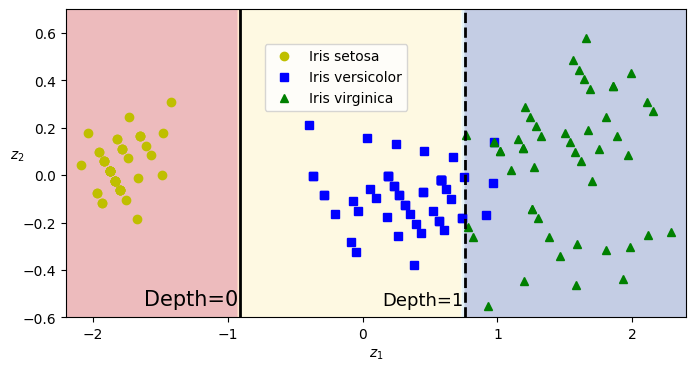

In [ ]:
# extra code – this cell generates and saves Figure 6–8

plt.figure(figsize=(8, 4))

axes = [-2.2, 2.4, -0.6, 0.7]
z0s, z1s = np.meshgrid(np.linspace(axes[0], axes[1], 100),
                       np.linspace(axes[2], axes[3], 100))
X_iris_pca_all = np.c_[z0s.ravel(), z1s.ravel()]
y_pred = tree_clf_pca.predict(X_iris_pca_all).reshape(z0s.shape)

plt.contourf(z0s, z1s, y_pred, alpha=0.3, cmap=plt.cm.RdYlBu)
for idx, (name, style) in enumerate(zip(iris.target_names, ("yo", "bs", "g^"))):
    plt.plot(X_iris_rotated[:, 0][y_iris == idx],
             X_iris_rotated[:, 1][y_iris == idx],
             style, label=f"Iris {name}")

plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
th1, th2 = tree_clf_pca.tree_.threshold[[0, 2]]
plt.plot([th1, th1], axes[2:], "k-", linewidth=2)
plt.plot([th2, th2], axes[2:], "k--", linewidth=2)
plt.text(th1 - 0.01, axes[2] + 0.05, "Depth=0",
         horizontalalignment="right", fontsize=15)
plt.text(th2 - 0.01, axes[2] + 0.05, "Depth=1",
         horizontalalignment="right", fontsize=13)
plt.axis(axes)
plt.legend(loc=(0.32, 0.67))
plt.show()

This plot shows the effect of PCA. After rotating the data, the classes are separated by straight vertical lines, so the tree can split them with simple cuts.

---


The DecisionTreeClassifier and DecisionTreeRegressor classes both support missing values natively,
`no need for an imputer.`


An imputer fills in missing values in a dataset. Missing entries (NaN) usually cause errors in scikit-learn models, so you replace them first, typically with the column’s mean, median, or most frequent value.

Eg-

```
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
X_filled = imputer.fit_transform(X)
```


---

### 5.2 Decision Trees have a High Variance

Decision Trees have High Variance which meeans small changes to the hyperparameters or to the data may produce different models.

Since ,The training algorithm used by Scikit-Learn is stochastic , which means,
* It randomly selects the set of the features to evaluate at each node - even retraining the same decision
tree on the exact same data may produce a very different model, (unless you set the `random_state Hyperparameter`).

In [ ]:
tree_clf_tweaked = DecisionTreeClassifier(max_depth=2, random_state=40)
tree_clf_tweaked.fit(X_iris_rotated, y_iris)

DecisionTreeClassifier(max_depth=2, random_state=40)

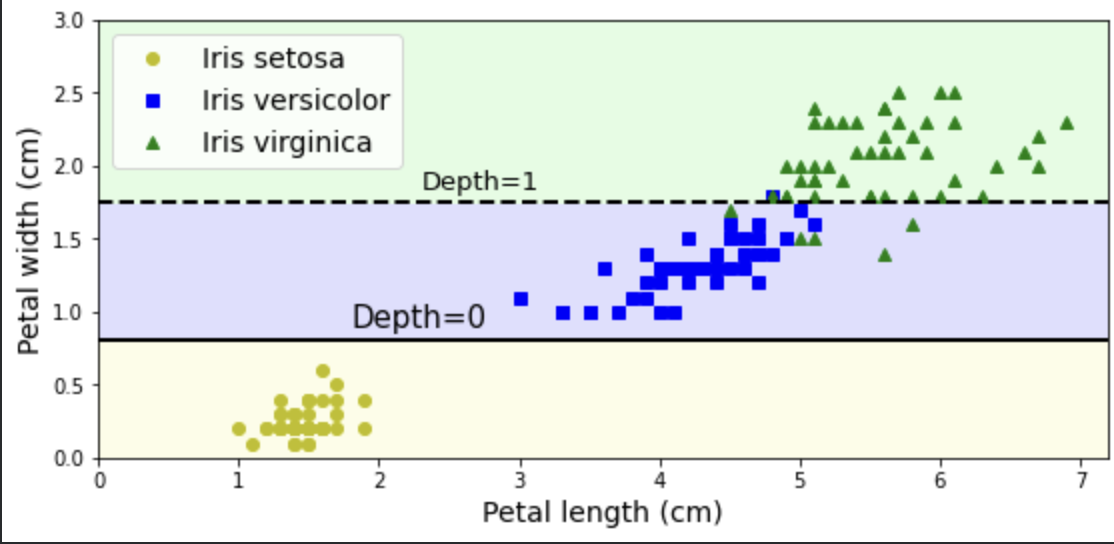

HERE is an example like we can see it looks different then the previous decision tree , with different random_state

Luckily, by averaging predictions over many trees, it’s possible to reduce variance significantly. Such an ensemble of
trees is called a random forest, and it’s one of the most powerful types of models available today.